# EDA — Default of Credit Card Clients
## Proyecto MLOps: Credit Default

**Objetivo:** explorar calidad, distribución, comportamiento de pagos y asociación con `default_payment_next_month` (1 = incumplimiento, 0 = no incumplimiento).

## 0. Librerías y configuración

In [4]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd
from scipy import stats
from sklearn.feature_selection import mutual_info_classif

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})

RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
RUTA = RAIZ / "data" / "default of credit clients.csv"
TARGET = "default_payment_next_month"
ID = "ID"

NUM_COLS = ["LIMIT_BAL", "AGE"] + [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]
ORD_COLS = ["EDUCATION", "MARRIAGE"] + [f"PAY_{i}" for i in [0, 2, 3, 4, 5, 6]]
CAT_COLS = ["SEX"]
FEATURES = [c for c in NUM_COLS + ORD_COLS + CAT_COLS if c != ID]
print("Ruta:", RUTA)

Ruta: c:\Users\ASUS\Actividad-2-MLOps\data\default of credit clients.csv


## 1. Carga y calidad de datos

In [5]:
RAIZ = Path.cwd()

RUTA = RAIZ / "data" / "default of credit card clients.csv"

# Si estás ejecutando desde notebooks, subir un nivel
if not RUTA.exists():
    RAIZ = Path.cwd().parent
    RUTA = RAIZ / "data" / "default of credit card clients.csv"

assert RUTA.exists(), f"No se encontró el CSV: {RUTA}"

df = pd.read_csv(
    RUTA,
    sep=";",
    encoding="utf-8",
    low_memory=False
)

df.columns = df.columns.str.strip().str.replace(" ", "_")

if "default_payment_next_month" not in df.columns:
    posibles = [
        c for c in df.columns
        if "default" in c.lower() and "next" in c.lower()
    ]
    if posibles:
        df = df.rename(columns={posibles[0]: "default_payment_next_month"})

TARGET = "default_payment_next_month"

assert TARGET in df.columns, f"No existe el objetivo {TARGET}"

print(f"Filas: {len(df):,} | Columnas: {df.shape[1]}")
display(df.head())


Filas: 30,000 | Columnas: 25


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_payment_next_month
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [6]:
calidad = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "unicos": df.nunique(),
    "ejemplo": df.iloc[0]
})
display(calidad)
print("Duplicados exactos:", df.duplicated().sum())
print("IDs duplicados:", df[ID].duplicated().sum() if ID in df else "ID no disponible")
display(df[TARGET].value_counts(dropna=False).rename("conteo").to_frame())

,tipo,nulos,unicos,ejemplo
ID,int64,0,30000,1
LIMIT_BAL,int64,0,81,20000
SEX,int64,0,2,2
EDUCATION,int64,0,7,2
MARRIAGE,int64,0,4,1
AGE,int64,0,56,24
PAY_0,int64,0,11,2
PAY_2,int64,0,11,2
PAY_3,int64,0,11,-1
PAY_4,int64,0,11,-1


Duplicados exactos: 0
IDs duplicados: 0


,conteo
default_payment_next_month,
0,23364
1,6636


## 2. Distribución de la variable objetivo

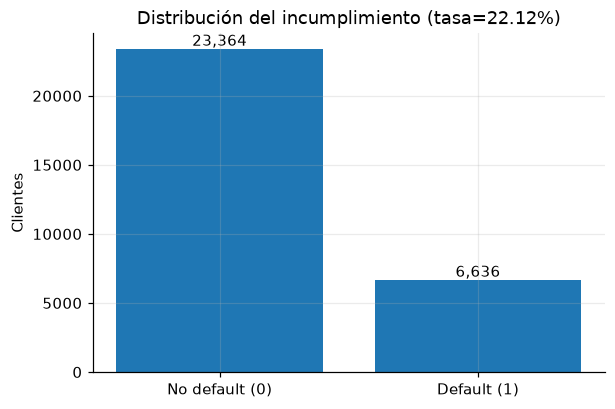

Tasa global de default: 22.12%


In [7]:
tasa_default = df[TARGET].mean()
conteo = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["No default (0)", "Default (1)"], conteo.values)
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_title(f"Distribución del incumplimiento (tasa={tasa_default:.2%})")
ax.set_ylabel("Clientes")
plt.show()
print(f"Tasa global de default: {tasa_default:.2%}")

## 3. EDA

In [8]:
desc = df[NUM_COLS].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["asimetria"] = df[NUM_COLS].skew()
desc["porcentaje_ceros"] = (df[NUM_COLS] == 0).mean() * 100
display(desc)

,count,mean,std,min,1%,25%,50%,75%,99%,max,asimetria,porcentaje_ceros
LIMIT_BAL,"30,000.000","167,484.323","129,747.662","10,000.000","10,000.000","50,000.000","140,000.000","240,000.000","500,000.000","1,000,000.000",0.993,0.000
AGE,"30,000.000",35.486,9.218,21.000,22.000,28.000,34.000,41.000,60.000,79.000,0.732,0.000
BILL_AMT1,"30,000.000","51,223.331","73,635.861","-165,580.000",-81.000,"3,558.750","22,381.500","67,091.000","350,110.680","964,511.000",2.664,6.693
BILL_AMT2,"30,000.000","49,179.075","71,173.769","-69,777.000",-200.000,"2,984.750","21,200.000","64,006.250","337,495.280","983,931.000",2.705,8.353
BILL_AMT3,"30,000.000","47,013.155","69,349.387","-157,264.000",-200.000,"2,666.250","20,088.500","60,164.750","325,030.390","1,664,089.000",3.088,9.567
BILL_AMT4,"30,000.000","43,262.949","64,332.856","-170,000.000",-212.020,"2,326.750","19,052.000","54,506.000","304,997.270","891,586.000",2.822,10.650
BILL_AMT5,"30,000.000","40,311.401","60,797.156","-81,334.000",-232.010,"1,763.000","18,104.500","50,190.500","285,868.330","927,171.000",2.876,11.687
BILL_AMT6,"30,000.000","38,871.760","59,554.108","-339,603.000",-331.030,"1,256.000","17,071.000","49,198.250","279,505.060","961,664.000",2.847,13.400
PAY_AMT1,"30,000.000","5,663.581","16,563.280",0.000,0.000,"1,000.000","2,100.000","5,006.000","66,522.180","873,552.000",14.668,17.497
PAY_AMT2,"30,000.000","5,921.163","23,040.870",0.000,0.000,833.000,"2,009.000","5,000.000","76,651.020","1,684,259.000",30.454,17.987


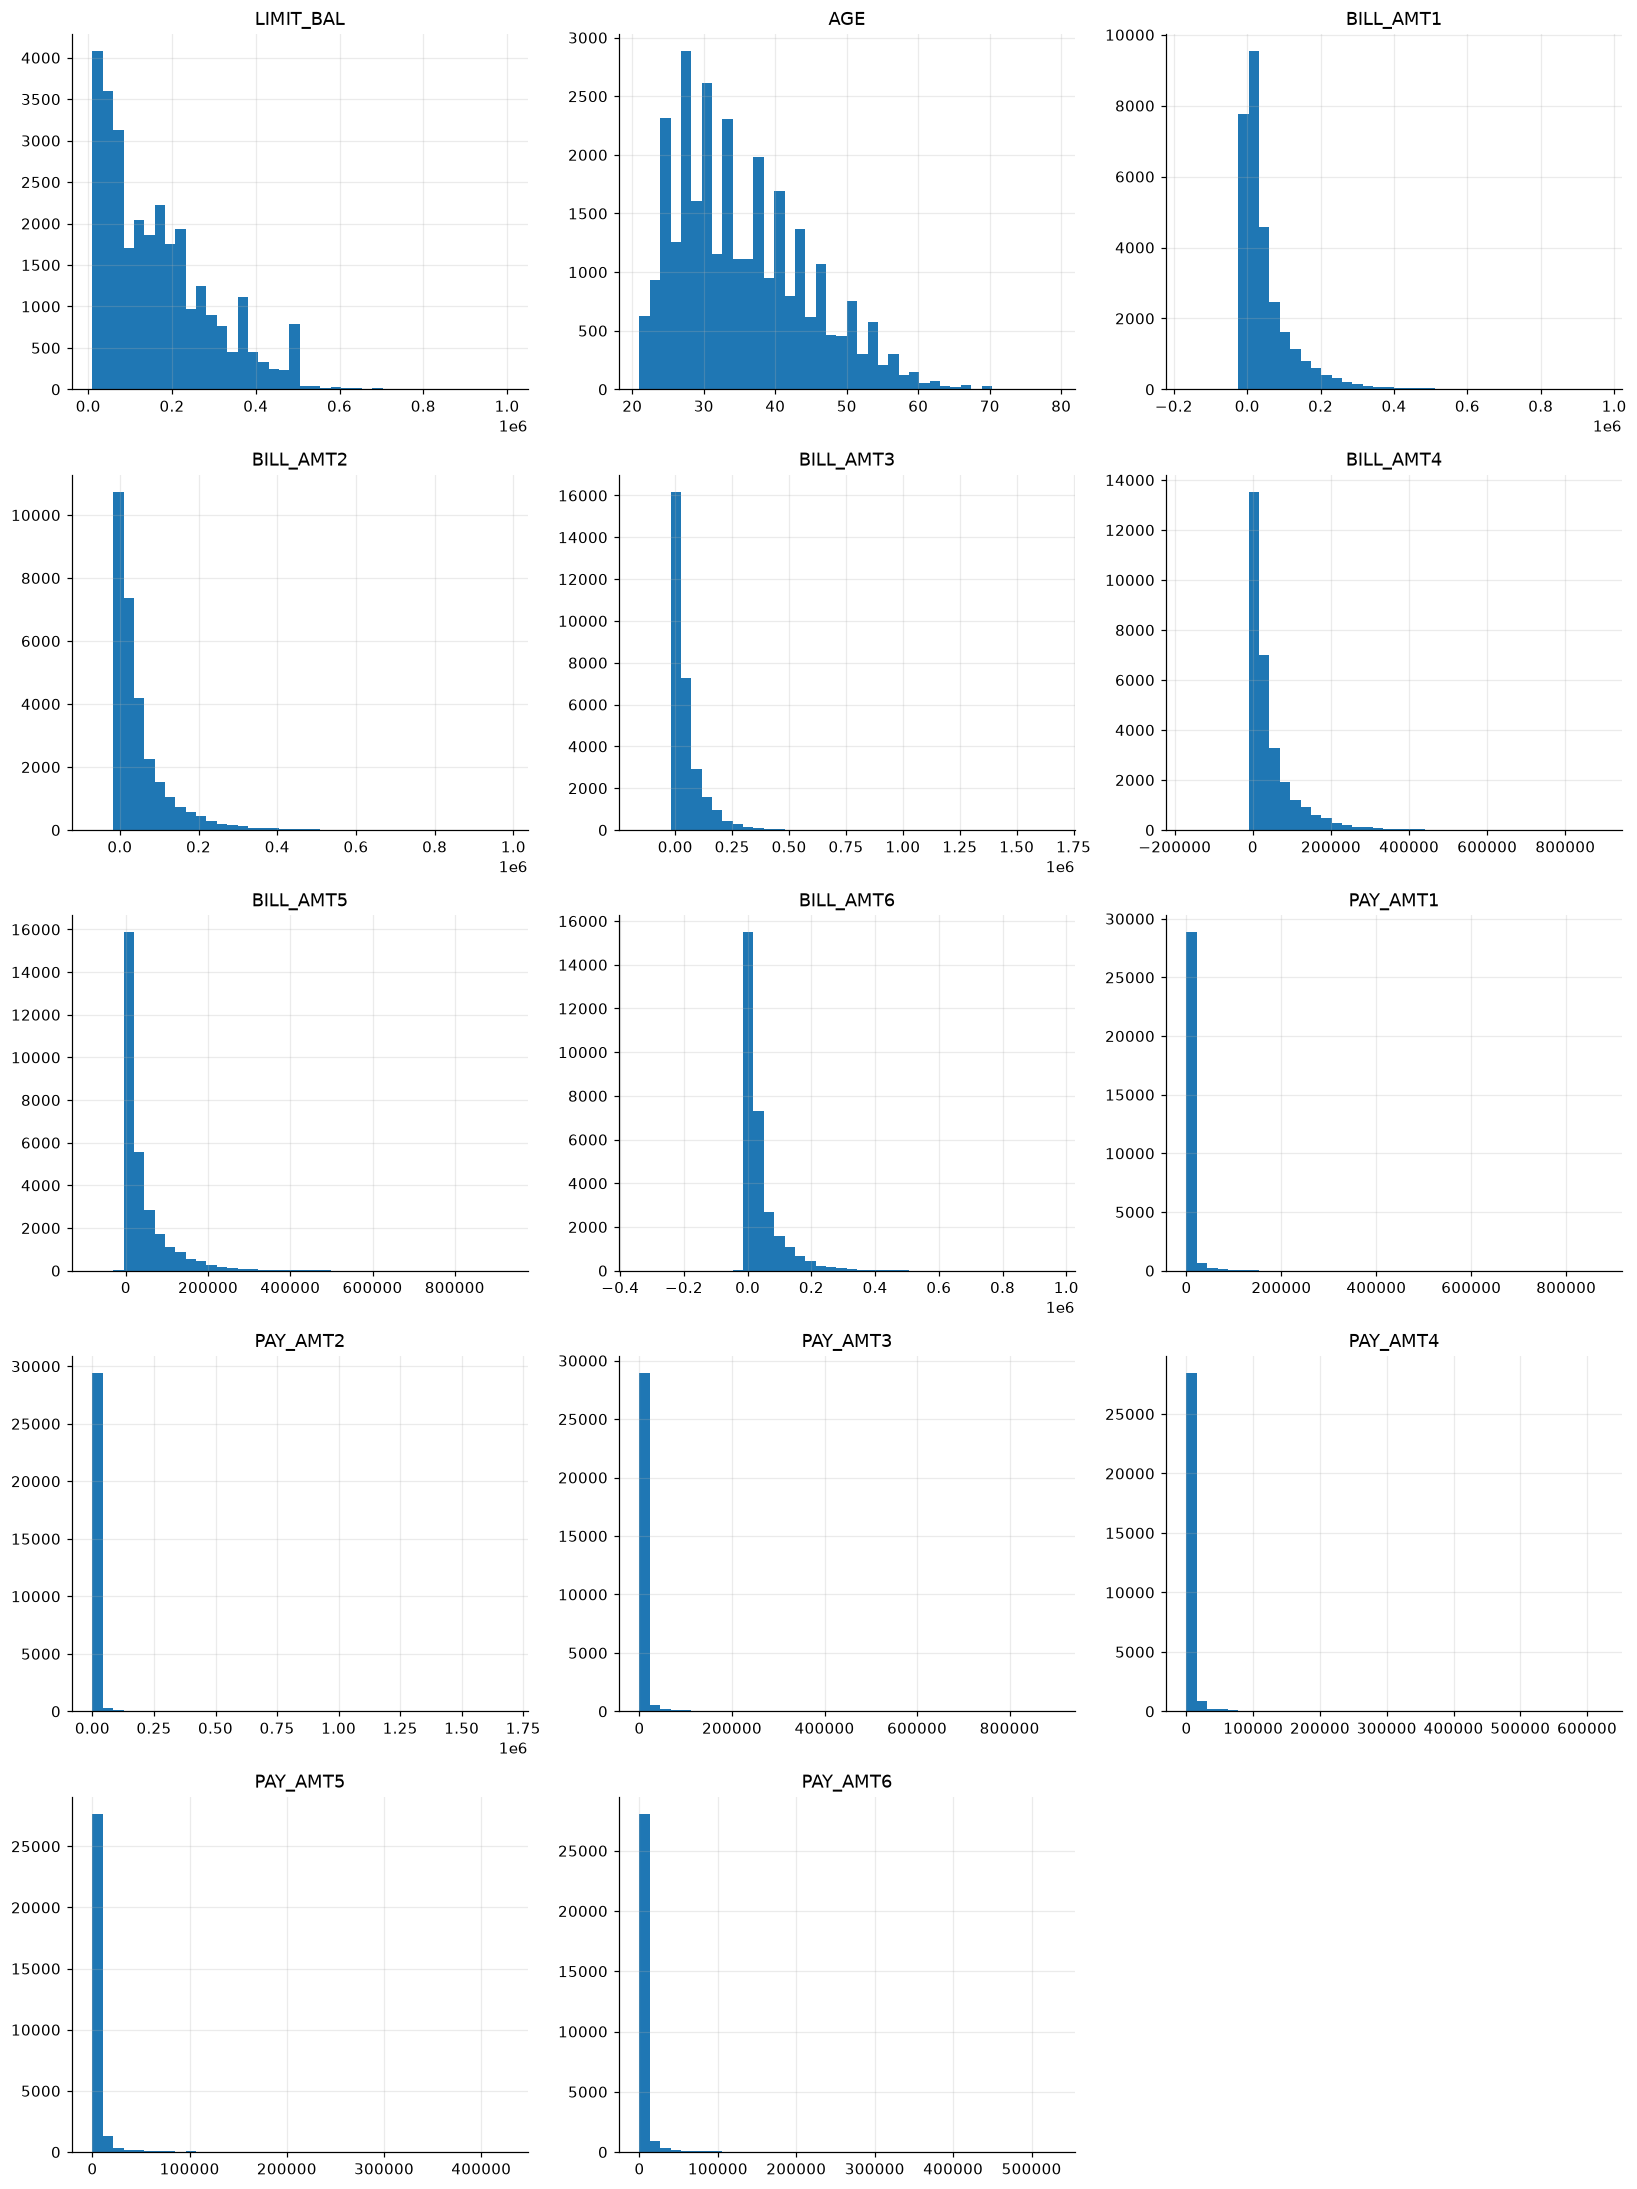

In [9]:
ncols=3
nrows=int(np.ceil(len(NUM_COLS)/ncols))
fig, axes=plt.subplots(nrows,ncols,figsize=(15,4*nrows))
for ax,col in zip(axes.ravel(),NUM_COLS):
    ax.hist(df[col].dropna(),bins=40)
    ax.set_title(col)
for ax in axes.ravel()[len(NUM_COLS):]: ax.set_visible(False)
fig.tight_layout(); plt.show()

## 4. Comparación por clase: incumplimiento vs no incumplimiento

In [10]:
filas=[]
for col in NUM_COLS:
    a=df.loc[df[TARGET]==0,col].dropna()
    b=df.loc[df[TARGET]==1,col].dropna()
    _,p=stats.mannwhitneyu(a,b,alternative="two-sided")
    filas.append({"variable":col,"mediana_no_default":a.median(),"mediana_default":b.median(),
                  "media_no_default":a.mean(),"media_default":b.mean(),"p_valor":p})
comparacion=pd.DataFrame(filas).set_index("variable")
display(comparacion.sort_values("mediana_default"))

,mediana_no_default,mediana_default,media_no_default,media_default,p_valor
variable,,,,,
AGE,34.000,34.000,35.417,35.726,0.373
PAY_AMT6,"1,706.000","1,000.000","5,719.372","3,441.482",0.000
PAY_AMT5,"1,765.000","1,000.000","5,248.220","3,219.140",0.000
PAY_AMT4,"1,734.000","1,000.000","5,300.529","3,155.627",0.000
PAY_AMT3,"2,000.000","1,222.000","5,753.497","3,367.352",0.000
PAY_AMT2,"2,247.500","1,533.500","6,640.465","3,388.650",0.000
PAY_AMT1,"2,459.500","1,636.000","6,307.337","3,397.044",0.000
BILL_AMT6,"16,679.000","18,028.500","39,042.269","38,271.436",0.989
BILL_AMT5,"17,998.000","18,478.500","40,530.445","39,540.190",0.235


## 5. Variables categóricas/discretas y tasa de default

In [11]:
def tabla_default(col):
    t=df.groupby(col,observed=True)[TARGET].agg(clientes="size",defaults="sum",tasa_default="mean")
    t["tasa_default_%"]=100*t["tasa_default"]
    t["lift_global"]=t["tasa_default"]/tasa_default
    return t.drop(columns="tasa_default")

for col in ["SEX","EDUCATION","MARRIAGE"]+[f"PAY_{i}" for i in [0,2,3,4,5,6]]:
    print("\\n---",col,"---")
    display(tabla_default(col))

\n--- SEX ---


,clientes,defaults,tasa_default_%,lift_global
SEX,,,,
1,11888,2873,24.167,1.093
2,18112,3763,20.776,0.939


\n--- EDUCATION ---


,clientes,defaults,tasa_default_%,lift_global
EDUCATION,,,,
0,14,0,0.000,0.000
1,10585,2036,19.235,0.870
2,14030,3330,23.735,1.073
3,4917,1237,25.158,1.137
4,123,7,5.691,0.257
5,280,18,6.429,0.291
6,51,8,15.686,0.709


\n--- MARRIAGE ---


,clientes,defaults,tasa_default_%,lift_global
MARRIAGE,,,,
0,54,5,9.259,0.419
1,13659,3206,23.472,1.061
2,15964,3341,20.928,0.946
3,323,84,26.006,1.176


... (8 outputs left out)

\n--- PAY_5 ---


,clientes,defaults,tasa_default_%,lift_global
PAY_5,,,,
-2,4546,895,19.688,0.890
-1,5539,897,16.194,0.732
0,16947,3195,18.853,0.852
2,2626,1423,54.189,2.450
3,178,113,63.483,2.870
4,84,51,60.714,2.745
5,17,10,58.824,2.659
6,4,3,75.000,3.391
7,58,48,82.759,3.741


\n--- PAY_6 ---


,clientes,defaults,tasa_default_%,lift_global
PAY_6,,,,
-2,4895,981,20.041,0.906
-1,5740,975,16.986,0.768
0,16286,3069,18.844,0.852
2,2766,1401,50.651,2.290
3,184,118,64.130,2.899
4,49,31,63.265,2.860
5,13,7,53.846,2.434
6,19,14,73.684,3.331
7,46,38,82.609,3.735


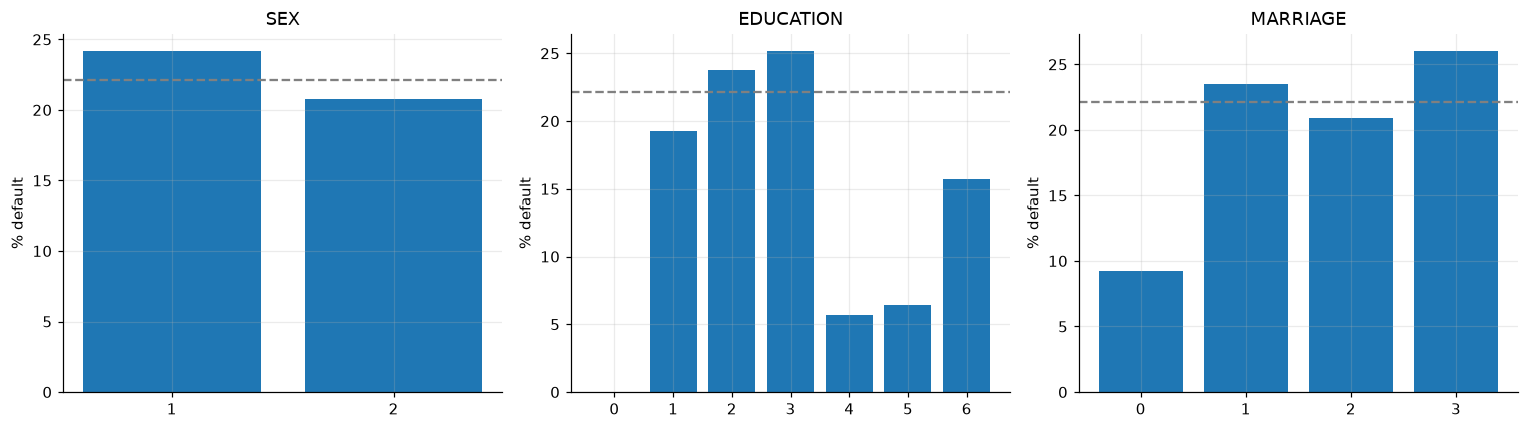

In [12]:
cols=["SEX","EDUCATION","MARRIAGE"]
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,col in zip(axes,cols):
    t=tabla_default(col)
    ax.bar(t.index.astype(str),t["tasa_default_%"])
    ax.axhline(tasa_default*100,ls="--",color="gray")
    ax.set_title(col); ax.set_ylabel("% default")
plt.tight_layout(); plt.show()

## 6. Asociación categórica: chi-cuadrado y V de Cramér

In [13]:
def cramers_v(col):
    tab=pd.crosstab(df[col],df[TARGET])
    chi2,p,_,_=stats.chi2_contingency(tab)
    n=tab.values.sum(); r,k=tab.shape
    v=np.sqrt(chi2/(n*(min(r,k)-1)))
    return v,p
res={c:cramers_v(c) for c in ["SEX","EDUCATION","MARRIAGE"]+[f"PAY_{i}" for i in [0,2,3,4,5,6]]}
asoc=pd.DataFrame(res,index=["cramers_v","p_valor"]).T.sort_values("cramers_v",ascending=False)
display(asoc)

,cramers_v,p_valor
PAY_0,0.423,0.000
PAY_2,0.340,0.000
PAY_3,0.296,0.000
PAY_4,0.279,0.000
PAY_5,0.271,0.000
PAY_6,0.251,0.000
EDUCATION,0.074,0.000
SEX,0.040,0.000
MARRIAGE,0.034,0.000


## 7. Correlaciones y relación con el objetivo

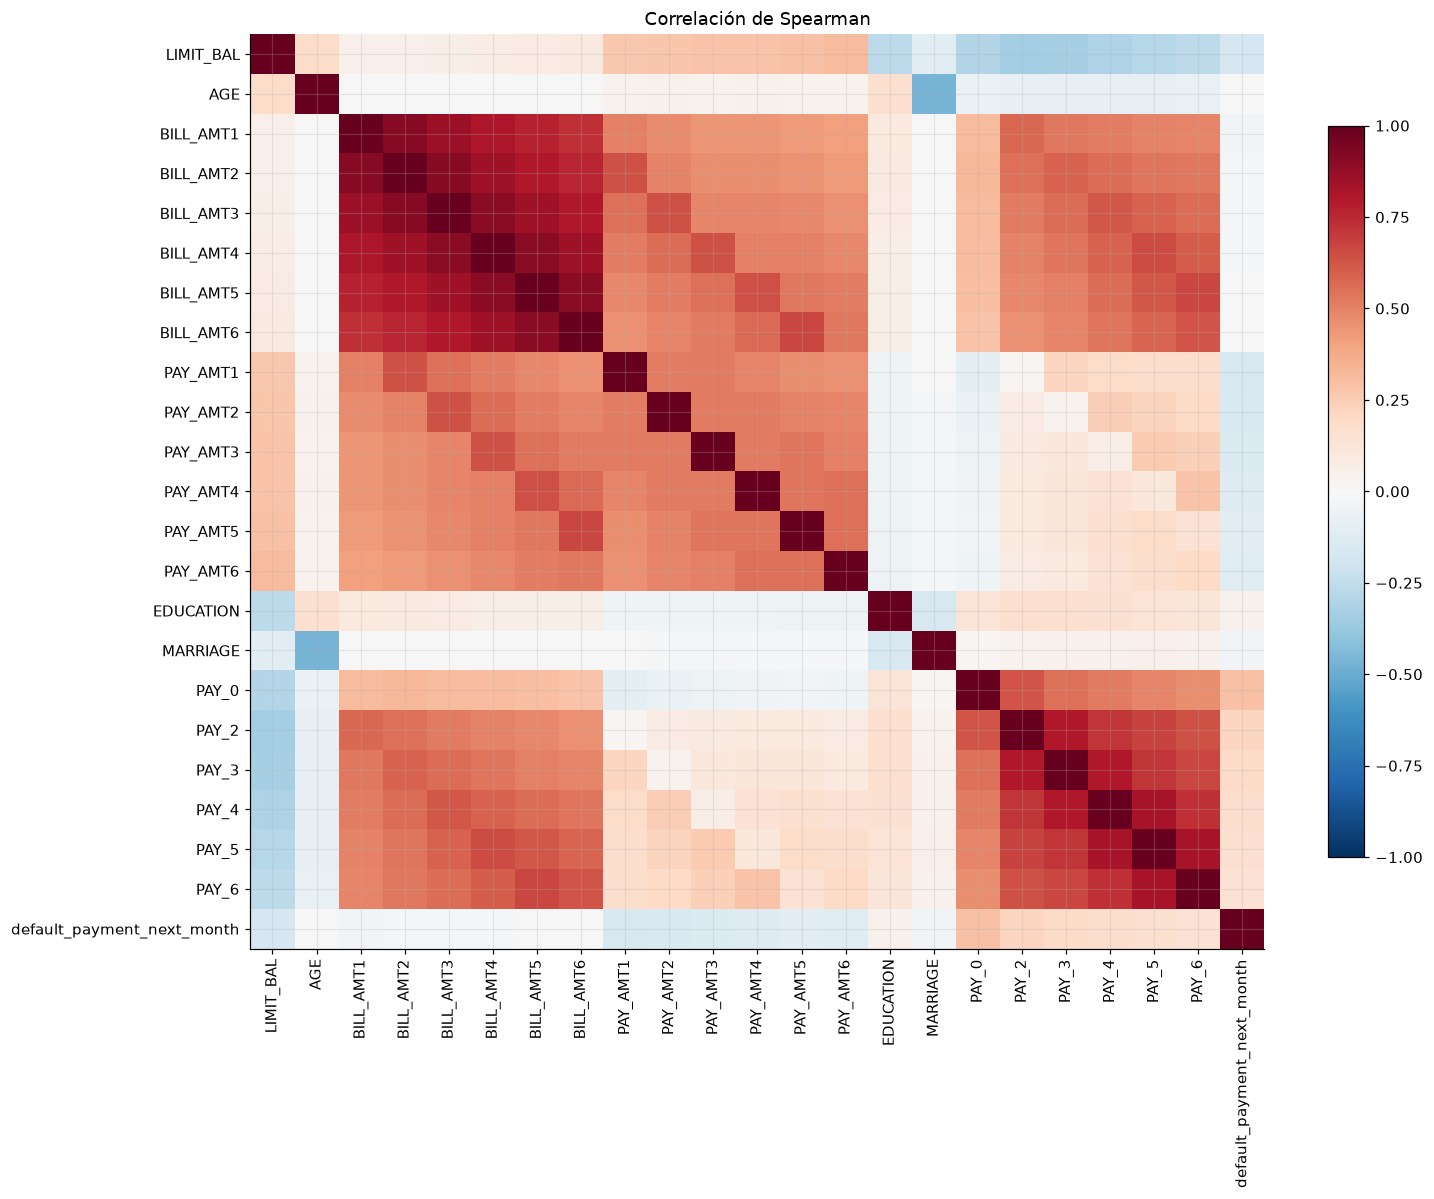

,spearman_con_default
PAY_0,0.292
PAY_2,0.217
PAY_3,0.195
PAY_4,0.174
LIMIT_BAL,-0.170
PAY_AMT1,-0.160
PAY_5,0.159
PAY_AMT2,-0.151
PAY_6,0.143
PAY_AMT3,-0.139


In [14]:
corr_cols=NUM_COLS+ORD_COLS+[TARGET]
corr=df[corr_cols].corr(method="spearman")
fig,ax=plt.subplots(figsize=(14,11))
im=ax.imshow(corr.values,cmap="RdBu_r",vmin=-1,vmax=1,aspect="auto")
ax.set_xticks(range(len(corr_cols))); ax.set_xticklabels(corr_cols,rotation=90)
ax.set_yticks(range(len(corr_cols))); ax.set_yticklabels(corr_cols)
fig.colorbar(im,ax=ax,shrink=.8); ax.set_title("Correlación de Spearman")
plt.tight_layout(); plt.show()
display(corr[TARGET].drop(TARGET).sort_values(key=abs,ascending=False).to_frame("spearman_con_default"))

## 8. Información mutua

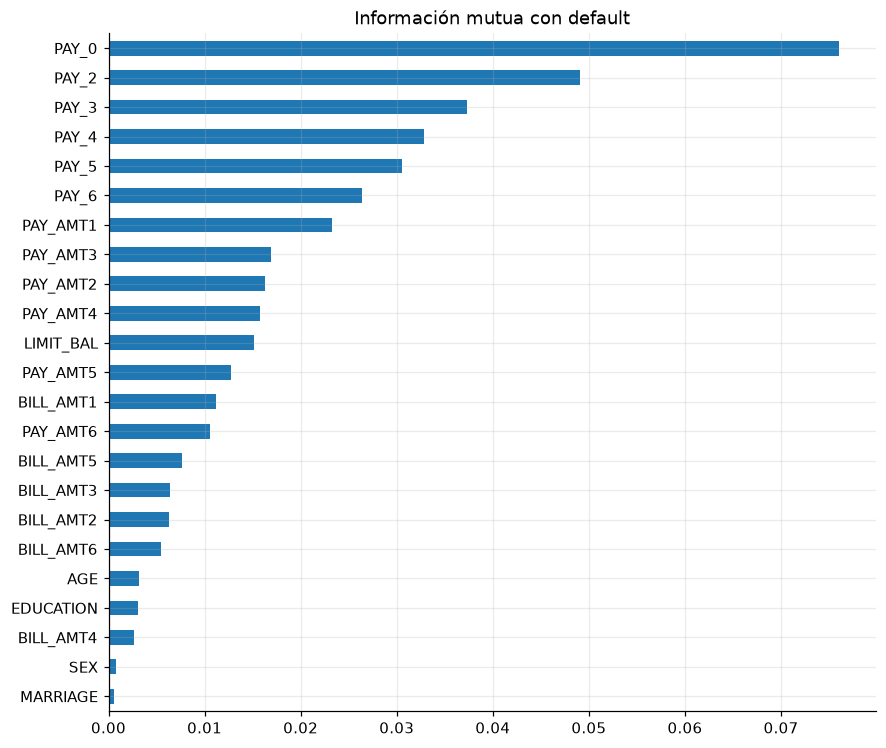

,informacion_mutua
PAY_0,0.076
PAY_2,0.049
PAY_3,0.037
PAY_4,0.033
PAY_5,0.031
PAY_6,0.026
PAY_AMT1,0.023
PAY_AMT3,0.017
PAY_AMT2,0.016
PAY_AMT4,0.016


In [15]:
Xmi=df[FEATURES].copy()
for c in CAT_COLS:
    Xmi[c]=Xmi[c].astype("category").cat.codes
discretas=[c in CAT_COLS+ORD_COLS for c in FEATURES]
mi=mutual_info_classif(Xmi,df[TARGET],discrete_features=discretas,random_state=42)
info=pd.Series(mi,index=FEATURES,name="informacion_mutua").sort_values()
info.plot(kind="barh",figsize=(9,8),title="Información mutua con default")
plt.show()
display(info.sort_values(ascending=False).to_frame())

## 9. Conclusiones para modelado

- `ID` se conserva para trazabilidad, pero **no debe usarse como predictor**.
- La etiqueta es `default_payment_next_month`; no incluirla en `X`.
- `PAY_0` y `PAY_2`–`PAY_6` reflejan estados de pago/retraso y suelen aportar señal predictiva.
- Revisar el desbalance de clases y reportar AUC, precision, recall y F1, no solo accuracy.
- Este EDA es descriptivo; asociación estadística no implica causalidad.